In [1]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd

rng = np.random.default_rng(100)

def purchase_probability(price):
    price = np.asarray(price, dtype=float)
    return (
        0.55 * np.exp(-np.logaddexp(0.0, (price - 13.9) / 0.8))
        + 0.30 * np.exp(-np.logaddexp(0.0, (price - 30.9) / 1.2))
        + 0.15 * np.exp(-np.logaddexp(0.0, (price - 58.4) / 1.8))
    )

def sales(price=14.0, rng=None, mean_customers=30):
    price = float(price)
    if not np.isfinite(price):
        raise ValueError("price must be finite")
    if price < 0:
        raise ValueError("price must be nonnegative")
    mean_customers = float(mean_customers)
    if not np.isfinite(mean_customers) or mean_customers < 0:
        raise ValueError("mean_customers must be finite and nonnegative")
    rng = np.random.default_rng(rng)
    customer_count = rng.poisson(mean_customers)
    probability = purchase_probability(price)
    return rng.binomial(1, probability, size=customer_count).astype(np.int8)

## Sequential Experimentation

- In the real world, we have to make decisions in real time
- Data arrive as we're taking action, and we have to update our behavior
- We're going to look at a simple $Z$-test, and investigate some options for search

## Revenue
- The **revenue** at a price $p$ is
$$
R(p) = \text{sales}(p) \times p
$$
- Sellers typically want to maximize revenue (or profit): Raising $p$ slightly increases the price paid for each unit sold, but reduces the number of units sold. A revenue-maximizing price must satisfy:
$$
R'(p^*) = \underbrace{\text{sales}(p^*) \times 1}_{\text{Increased revenue per sale}}+ \underbrace{\left.\dfrac{d \text{sales}(p)}{dp}\right|_{p=p^*}}_{\text{Lost marginal sales}} \times p^* = 0
$$
- This helps us think about trade-offs, but this is an idealized thought experiment: The world doesn't actually give us a `sales` function

## Revenue Management
- In the real world, we don't observe the $\text{sales}(p)$ function directly (you might model it, and we'll do that eventually, but a company like Uber often relies on experiments to adjust prices)
- Instead, you simply see how customers respond to changes in your pricing
- But changes in revenue are hard to attribute to a negative causal impact on sales, versus simply fewer customers engaging that day
- The lab is built around observing behavior, testing a hypothesis, and then updating prices
- This is called **stochastic optimization**: Each price you set is an experiment that yields information

## Key Function: `sales`
- The `sales(price=14.0, rng=None, mean_customers=30)` function is the core of the lab
- `mean_customers` scales the size of the market up and down: You'll want to be able to easily control the number of customers you experiment with later
- The rng argument is the numpy random number generator to use
- You set a `price`, and it returns a vector of customer choices (0=didn't buy, 1=buy) with a mean of your requested experiment size, `mean_customers`

## 1. Comparing Two Prices
- Our `sales(price, rng)` function generates a number of customers and their sales choices
- The number of customers who "browse" isn't affect by the price you choose, but whether they purchase is effected: Higher prices lead to lower sales
- Because sales are random/stochastic, it's difficult to know whether a change in price is truly profitable or not

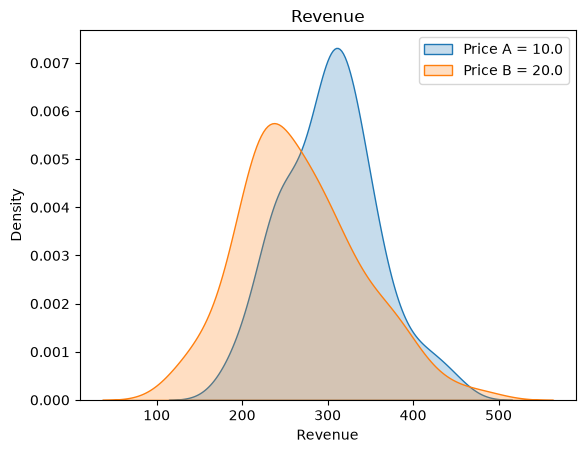

In [2]:
R = 100 # Test each price for 100 days
p_A = 10.0
p_B = 20.0
revenue_A = [ sales(p_A, rng=rng).sum() * p_A for t in range(R) ]
revenue_B = [ sales(p_B, rng=rng).sum() * p_B for t in range(R) ]
sns.kdeplot(revenue_A, fill=True, label=f"Price A = {p_A}").set(title=f"Revenue", xlabel="Revenue", ylabel="Density")
sns.kdeplot(revenue_B, fill=True, label=f"Price B = {p_B}")
plt.legend()

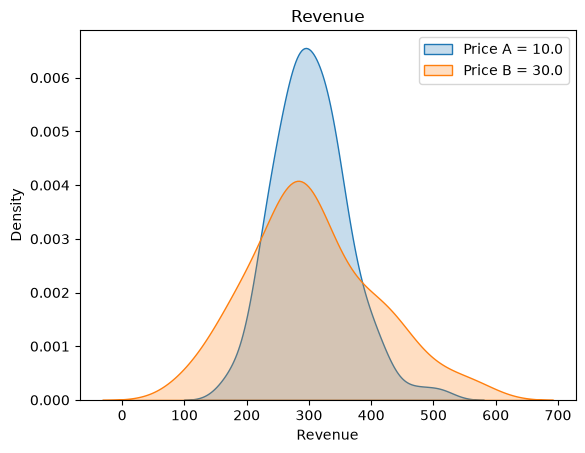

In [3]:
R = 100 # Test each price for 100 days
p_A = 10.0
p_B = 30.0
revenue_A = [ sales(p_A, rng=rng).sum() * p_A for t in range(R) ]
revenue_B = [ sales(p_B, rng=rng).sum() * p_B for t in range(R) ]
sns.kdeplot(revenue_A, fill=True, label=f"Price A = {p_A}").set(title=f"Revenue", xlabel="Revenue", ylabel="Density")
sns.kdeplot(revenue_B, fill=True, label=f"Price B = {p_B}")
plt.legend()

## Two-Sample $Z$-Test
- How can we compare revenue at two different price points?
- In the diabetes management lab, we used a fully non-parametric approach to comparing metformin versus rostiglatzione versus lifestyle
- Now that we know more about how Bootstrapping and classical inference interact, we can convert that two-way comparison into a statistical test
- The key fact to know is that if $X$ and $Y$ are independent and normally distributed with means $\mu_X$ and $\mu_Y$ and standard deviations $\sigma_X$ and $\sigma_Y$, then $X-Y$ is normally distributed with mean $\mu_X - \mu_Y$ and standard deviation $\sqrt{\sigma_X^2 + \sigma_Y^2}$

## Two-Sample $Z$-Test
- For large samples, the CLT lets us apply the difference-of-normals reasoning to approximately Normal sample means
- So let $\bar{X}_{n_X}$ be the mean of a sample of IID random variables of size $n_X$ with means $\mu_X$ and standard deviations $\sigma_X$ (and similarly for $\bar{Y}_{n_Y}$)
- The expectation of $\bar{X}_{n_X}$ is $\mu_X$, and the standard deviation of $\bar{X}_{n_X}$ is $\sigma_X/\sqrt{n_X}$ (and similarly for $\bar{Y}_{n_Y}$)
- Then the difference in $\Delta = \bar{X}_{n_X}-\bar{Y}_{n_Y}$ is approximately Normally distributed, with mean $\mu_X - \mu_Y$ and standard deviation $\sqrt{\sigma_X^2/n_X + \sigma_Y^2/n_Y}$
- What happens to the standard error of the mean as $n_X$ or $n_Y$ increase?
- If $\mu_X - \mu_Y$ is close to zero, is a difference in means easier or more difficult to detect?

## CIs for the Two-Sample $Z$-Test
- So the idea is: If $\bar{X}_{n_X}-\bar{Y}_{n_Y}$ has an approximately Normal sampling distribution with mean $\mu_X - \mu_Y$ and approximate the standard error with $\sqrt{\sigma_X^2/n_X + \sigma_Y^2/n_Y}$, we can compute, for instance, a 90% CI against a null of zero with
$$
\left( (\bar{X}_{n_X}-\bar{Y}_{n_Y}) - 1.645 \times \sqrt{\frac{s_X^2}{n_X} + \frac{s_Y^2}{n_Y}}, \quad (\bar{X}_{n_X}-\bar{Y}_{n_Y}) + 1.645 \times \sqrt{\frac{s_X^2}{n_X} + \frac{s_Y^2}{n_Y}} \right)
$$
- If 0 is in the interval, we can't distinguish whether the $X$ group has a higher or lower mean than the $Y$ group (fail to reject the null hypothesis). If 0 is not in the interval, it provides evidence against the null (reject the null hypothesis) and the $X$ and $Y$ groups are exhibiting statistically significant differences in outcomes 

<img src="./src/2szt.png" width="800px">

## Testing a Change in Price
- Let's compare prices of 10.00 and 15.00
- We'll draw a sample of customers at 10.00 and another at 15.00, and see what happens to revenue/customer

In [4]:
p_A = 10.00
p_B = 15.00
size = 100

sales_A = sales(p_A, mean_customers=size, rng=rng) * p_A # Compute revenue for each customer in A
sales_B = sales(p_B, mean_customers=size, rng=rng) * p_B # Compute revenue for each customer in B

print(f'There are {len(sales_A)} customers in A and {len(sales_B)} customers in B')

revenue_A = sales_A.mean() # Mean revenue per arriving customer in A
revenue_B = sales_B.mean() # Mean revenue per arriving customer in B

delta_R = revenue_B - revenue_A # Difference in mean revenue per arriving customer
std_error = np.sqrt(
    np.var(sales_A, ddof=1) / len(sales_A) +
    np.var(sales_B, ddof=1) / len(sales_B)
) # Standard Error

print(f'Change in mean revenue/customer is {delta_R:.3f} with standard error {std_error:.3f}')
confidence_interval = (delta_R - 1.96 * std_error, delta_R + 1.96 * std_error)
print(f"95% confidence interval for the difference in mean revenue/customer: ({confidence_interval[0]:.3f}, {confidence_interval[1]:.3f})")

There are 103 customers in A and 90 customers in B
Change in mean revenue/customer is -1.236 with standard error 0.791
95% confidence interval for the difference in mean revenue/customer: (-2.787, 0.315)


## Increasing the Sample Size
- But we're only getting handfuls of observations?
- There's a lot of noise here
- Set `experiment_size` to 100, 200, and 500 in turn; rerun the next experiment and power cells for each setting
- Each run computes 100 separate 90% confidence intervals

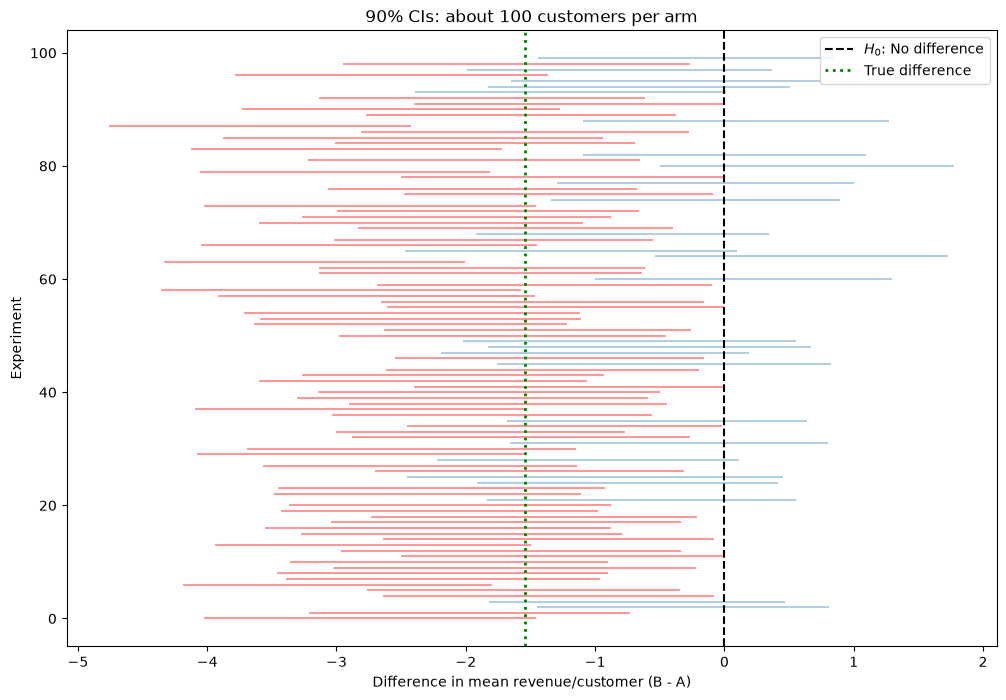

In [5]:
p_A = 10.00
p_B = 15.00
experiment_size = 100
CIs = []
for i in range(100):
    sales_A = sales(p_A, mean_customers = experiment_size, rng=rng) * p_A # Compute revenue for each customer in A
    sales_B = sales(p_B, mean_customers = experiment_size, rng=rng) * p_B # Compute revenue for each customer in B
    revenue_A = sales_A.mean() # Mean revenue per arriving customer in A
    revenue_B = sales_B.mean() # Mean revenue per arriving customer in B
    delta_R = revenue_B - revenue_A # Difference in mean revenue per arriving customer
    std_error = np.sqrt(
        np.var(sales_A, ddof=1) / len(sales_A) +
        np.var(sales_B, ddof=1) / len(sales_B)
    ) # Standard Error
    confidence_interval = (delta_R - 1.645 * std_error, delta_R + 1.645 * std_error)
    CIs.append(confidence_interval)

CIs = np.array(CIs)

fig, ax = plt.subplots(figsize=(12, 8))

for i, (lower, upper) in enumerate(CIs):
    ax.hlines(
        y=i,
        xmin=lower,
        xmax=upper,
        color='steelblue' if lower <= 0 <= upper else 'red',
        alpha=0.4,
        linewidth=1.5
    )

ax.axvline(0, color='black', linestyle='--', label='$H_0$: No difference')

# Model-based truth for checking coverage, not an estimate from these experiments.
true_delta = p_B * purchase_probability(p_B) - p_A * purchase_probability(p_A)
ax.axvline(
    true_delta,
    color='green',
    linestyle=':',
    linewidth=2,
    label='True difference'
)

ax.set_xlabel('Difference in mean revenue/customer (B - A)')
ax.set_ylabel('Experiment')
ax.set_title(f'90% CIs: about {experiment_size} customers per arm')
ax.legend()

plt.show()

## Statistical Power
- Our CIs cover the true param about 90% of the time, as they should, but whether or not we reject the null of 0 depends on the size of the experiment (the number of customers we experiment on)
- We define **(empirical) power** as
$$
\widehat{\text{Power}} = \dfrac{\text{Number of CIs excluding zero}}{\text{Number of Experiments}}
$$
and **(empirical) coverage** as
$$
\widehat{\text{Coverage}} = \dfrac{\text{Number of CIs including the true parameter value}}{\text{Number of Experiments}}
$$
- So you can see that as we increase the mean customers per experiment, the power increases significantly
- A nonsignificant result from an underpowered experiment does not establish that there is no effect
- Larger experiments require more customers and time, potentially spent at suboptimal prices
- Especially if the changes in price are small, the experiment will need to be powered to detect changes in revenue
- Potential gains from adjusting the price must be weighed against the cost of the experiment

In [6]:
power = np.mean(
    (CIs[:, 0] > 0) | (CIs[:, 1] < 0)
)
print(f"Empirical power: {power:.3%}")

coverage = np.mean(
    (CIs[:, 0] <= true_delta) & (CIs[:, 1] >= true_delta)
)
print(f"Empirical coverage/confidence (around 90%): {coverage:.3%}")


Empirical power: 74.000%
Empirical coverage/confidence (around 90%): 84.000%


## Power versus Confidence
- So the power varies with the size of the experiment: We're comparing to a null of zero
- Empirical coverage stays around 90%, with simulation noise and Normal-approximation error: We're cheating, and asking if the true value of the parameter is included in the interval
- This should help resolve a bit of the confusion around what confidence intervals are and how hypothesis testing works

## 2. Searching for the Optimal Price
- We have two broad strategies for searching for the optimal price:
    1. Grid Search: Pick a grid between 0 and 150, evaluate each price, and compare estimated revenue.
    2. Local Search: Use gradient ascent. Compare two nearby prices, $p_t-h$ and $p_t+h$, using fresh, independent customer samples:
    $$
    \hat g_t = \frac{\hat r(p_t+h)-\hat r(p_t-h)}{2h},
    \qquad p_{t+1}=p_t+\ell_t\hat g_t.
    $$
- Here $\hat r(p)$ is observed mean revenue per arriving customer, $h$ is the step size, and $\ell_t$ is the learning rate.
- Because expected traffic is independent of price, maximizing expected revenue per customer also maximizes expected total revenue for the same market size.
- The code clips prices to $[0,75]$, adjusts the slope denominator at the boundaries, and limits each move to 2 price units.
- A 90% interval containing zero can reflect low power; it does not certify an optimum. We use a fixed iteration budget and reduce the learning rate over time.
- These are pointwise intervals for individual comparisons. Repeated adaptive testing does not provide an overall 90% guarantee for the selected price.


## Local Search
- You do not **have** to use local search based on the gradient: You could do something with sequential grid search
- Local search is potentially a powerful tool to refine your price in a neighborhood of the optimum, using inference and optimization together

In [7]:
def estimate_gradient(price, *, step=1.0, mean_customers=300, rng=None):
    if step <= 0:
        raise ValueError("step must be positive")
    rng = np.random.default_rng(rng)
    price = float(np.clip(price, 0, 75))
    price_low = max(0, price - step)
    price_high = min(75, price + step)
    low = price_low * sales(price_low, mean_customers=mean_customers, rng=rng)
    high = price_high * sales(price_high, mean_customers=mean_customers, rng=rng)
    if min(len(low), len(high)) < 2:
        raise ValueError("Need at least two customers per arm; increase mean_customers.")

    difference = high.mean() - low.mean()
    se = np.sqrt(low.var(ddof=1) / len(low) + high.var(ddof=1) / len(high))
    gap = price_high - price_low
    return {
        "price": price,
        "gradient": difference / gap,
        "gradient_se": se / gap,
        "ci_low": (difference - 1.645 * se) / gap,
        "ci_high": (difference + 1.645 * se) / gap,
        "customers": len(low) + len(high),
    }


# A positive slope suggests raising the price; a negative slope suggests lowering it.
local_experiment = estimate_gradient(price=30, rng=2026)
pd.DataFrame([local_experiment]).round(3)


,price,gradient,gradient_se,ci_low,ci_high,customers
0,30.0,-0.791,0.581,-1.747,0.165,607


In [8]:
def gradient_ascent(start_price, *, iterations=80, step=1.0,
                    learning_rate=2.0, mean_customers=300, seed=100):
    """Use a fixed experiment budget and a decreasing learning rate."""
    if iterations < 1:
        raise ValueError("iterations must be at least 1")
    search_rng = np.random.default_rng(seed)
    price = float(np.clip(start_price, 0, 75))
    records = []
    for iteration in range(iterations):
        estimate = estimate_gradient(price, step=step,
                                     mean_customers=mean_customers, rng=search_rng)
        rate = learning_rate / np.sqrt(iteration + 1)
        move = np.clip(rate * estimate["gradient"], -2.0, 2.0)
        next_price = float(np.clip(price + move, 0, 75))
        records.append({"iteration": iteration + 1, **estimate,
                        "learning_rate": rate, "next_price": next_price})
        price = next_price
    return pd.DataFrame(records)


path = gradient_ascent(start_price=32, seed=2058)
path[["iteration", "price", "gradient", "ci_low", "ci_high", "next_price"]].head(10)


,iteration,price,gradient,ci_low,ci_high,next_price
0,1,32.000000,-1.903697,-2.820153,-0.987240,30.000000
1,2,30.000000,-2.101038,-3.045292,-1.156785,28.000000
2,3,28.000000,-0.816932,-1.748906,0.115042,27.056688
3,4,27.056688,0.219296,-0.664990,1.103582,27.275984
4,5,27.275984,0.055137,-0.842240,0.952513,27.325300
5,6,27.325300,0.526859,-0.384295,1.438013,27.755479
6,7,27.755479,0.190000,-0.723219,1.103219,27.899105
7,8,27.899105,0.293042,-0.660448,1.246532,28.106317
8,9,28.106317,0.146214,-0.800387,1.092814,28.203793
9,10,28.203793,-0.077915,-0.967813,0.811983,28.154515


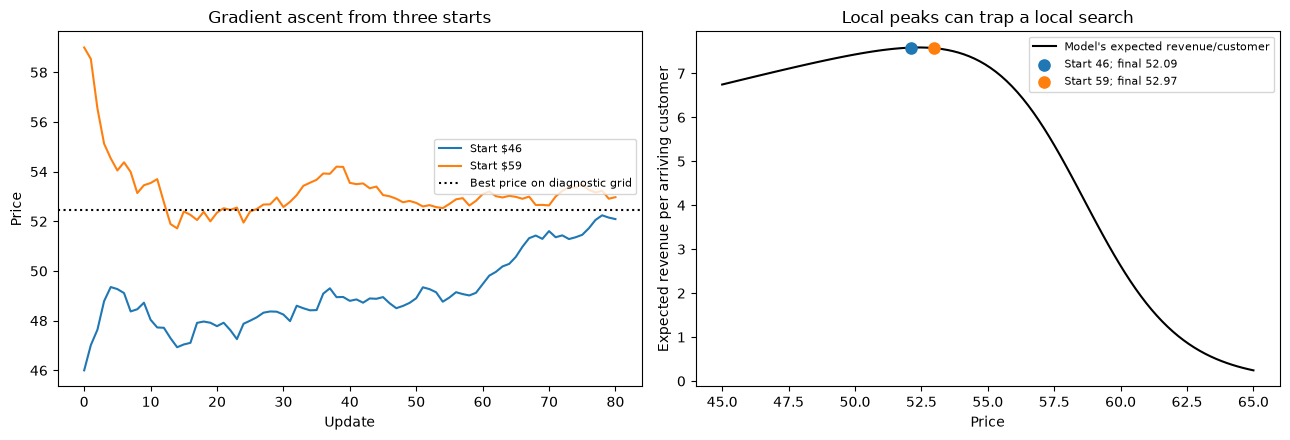

,start_price,final_price,search_customers,validation_customers,validation_revenue_per_customer,validation_se
0,46.0,52.091,47855,10036,7.547,0.183
1,59.0,52.973,47770,9894,7.678,0.187


In [11]:
# Only the diagnostic plot uses the model's true purchase curve.
# The search itself uses sales() at two nearby prices on every iteration.
starts = [46.0, 59.0]
ascent_paths = {
    start: gradient_ascent(start, seed=2026 + int(start))
    for start in starts
}
price_grid = np.linspace(45, 65, 100)
expected_revenue_per_customer = price_grid * purchase_probability(price_grid)
grid_best_price = price_grid[np.argmax(expected_revenue_per_customer)]

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
axes[1].plot(price_grid, expected_revenue_per_customer,
             color="black", label="Model's expected revenue/customer")
evaluation_rng = np.random.default_rng(9001)
summary = []
for index, (start, history) in enumerate(ascent_paths.items()):
    color = f"C{index}"
    prices = np.r_[start, history["next_price"].to_numpy()]
    final_price = prices[-1]
    axes[0].plot(np.arange(len(prices)), prices,
                 color=color, label=f"Start ${start:g}")
    axes[1].scatter(final_price, final_price * purchase_probability(final_price),
                    color=color, s=65, zorder=3,
                    label=f"Start {start:g}; final {final_price:.2f}")

    # Evaluate the selected price with fresh customers, outside the search data.
    validation = final_price * sales(final_price, mean_customers=10_000,
                                      rng=evaluation_rng)
    summary.append({
        "start_price": start,
        "final_price": final_price,
        "search_customers": int(history["customers"].sum()),
        "validation_customers": len(validation),
        "validation_revenue_per_customer": validation.mean(),
        "validation_se": validation.std(ddof=1) / np.sqrt(len(validation)),
    })

axes[0].axhline(grid_best_price, color="black", linestyle=":",
                label="Best price on diagnostic grid")
axes[0].set(xlabel="Update", ylabel="Price", title="Gradient ascent from three starts")
axes[1].set(xlabel="Price", ylabel="Expected revenue per arriving customer",
            title="Local peaks can trap a local search")
axes[0].legend(loc="center right", bbox_to_anchor=(1, 0.62), fontsize=8)
axes[1].legend(fontsize=8)
fig.tight_layout()
plt.show()

pd.DataFrame(summary).round(3)


## Lab
- You submit an .ipynb or .py that does two things:
    1. Determines an optimal price algorithmically (your code searches for and discovers an optimal price)
    2. Tracks the total number of consumers you have experimented with (at the optimum, each consumer has an expected profit of $11.925)

- The optimal price is between 0 and 70: There is no reason to consider prices outside that range
- There are multiple prices that appear optimal, but only one is globally optimal

- Provide a 1-3 page write-up explaining your design, including tables and plots as necessary:
    1. A one-paragraph summary of the problem
    2. Two paragraphs about how your design handles uncertainty about changes in revenue and selects prices
    3. Two paragraphs about challenges you faced and how you resolved them
    4. One paragraph that summarizes your results. In particular, how many consumers did you experiment on, what were your revenues during the experiments, and what percentage of the optimal profit ($11.925 per customer) did you capture?


## Issues to Consider

- How much data do you want to gather?
- Do you really want 90/95/99% confidence for setting prices?
- How do you combine brute force grid search?
- What is the minimum step size between prices you want to test?
- How should you adjust your sample size based on the information you are getting at a given price?
- If you cache experiments, can you gather data incrementally to constrain costs?